# Vector Schrödinger PDE Residuals: Analytic, Discrete, and Quantum Backends

**Colin Casey, 2026.** Library: `dgs/vector_schrodinger_residual.py` (tests: `tests/test_vector_schrodinger_residual.py`). Follows `schrodinger_separation_industry.ipynb`, which did the scalar version.

## In plain words

Many systems carry a **two-level internal label** on top of position: spin up/down, two electronic states of a molecule, the two levels of an ion qubit, two coupled waveguide modes. The wavefunction becomes a 2-vector $\Psi=[\psi_1,\psi_2]^T$, and the potential becomes a $2\times2$ **Hermitian** matrix. The diagonal entries are each state's own potential; the off-diagonal entry couples the two states.

The **residual** is what is left when you plug a candidate $\Psi$ into the equation. Zero means it's a solution. This notebook keeps three different "residuals" apart:

| | what it is | where |
|---|---|---|
| **analytic residual** | exact SymPy expression; $0$ for a true solution | §2–§5 |
| **discretized residual** | finite differences on a grid; $O(\Delta x^2+\Delta t^2)$, never exactly 0 | §5–§6 |
| **quantum-simulation backend** | CUDA-Q / cuQuantum evolve a *qubit state* or contract tensors; they do **not** evaluate the PDE residual | §9–§10 |

Everything runs on CPU. CUDA-Q and cuQuantum are detected and used only if they are installed.

In [1]:
import sympy as sp
sp.init_printing()
import shutil, subprocess, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
try:
    import scipy
    print('scipy', scipy.__version__, 'available: sparse eigensolver and expm will be used')
except ImportError:
    scipy = None
    print('scipy not available: NumPy dense fallbacks will be used')
from dgs import vector_schrodinger_residual as vsr
x, t, hbar, m, omega, g, E = vsr.x, vsr.t, vsr.hbar, vsr.m, vsr.omega, vsr.g, vsr.E
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.max_colwidth', 80)

scipy 1.17.0 available: sparse eigensolver and expm will be used


## 1. Two-component wavefunction and Hermitian potential

$$\Psi(x,t)=\begin{bmatrix}\psi_1(x,t)\\ \psi_2(x,t)\end{bmatrix},\qquad
V(x,t)=\begin{bmatrix}V_{11}(x,t) & W(x,t)\\ W^*(x,t) & V_{22}(x,t)\end{bmatrix},\quad V_{11},V_{22}\in\mathbb R .$$

$V=V^\dagger$ ensures real energies and conserved total probability. Each field is written through real parts: $\psi_j=u_j+iv_j$ and $W=a+ib$.

In [2]:
Psi_g, V_g, R_g, f = vsr.general_residual()
display(Math(r'\Psi = ' + sp.latex(Psi_g)))
display(Math(r'V = ' + sp.latex(V_g)))
print('V Hermitian (V - V^dagger == 0):', vsr.is_hermitian(V_g))
print('control: [[0, i], [i, 0]] Hermitian:', vsr.is_hermitian(sp.Matrix([[0, sp.I], [sp.I, 0]])))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

V Hermitian (V - V^dagger == 0): True
control: [[0, i], [i, 0]] Hermitian: False


## 2. The time-dependent vector residual

$$\boxed{R=i\hbar\,\partial_t\Psi+\frac{\hbar^2}{2m}\partial_x^2\Psi-V\Psi}$$

Two coupled complex PDEs. $\psi_2$ enters $R_1$ only through $W$, and $\psi_1$ enters $R_2$ only through $W^*$.

In [3]:
for j in range(2):
    display(Math(rf'R_{j+1} = ' + sp.latex(sp.expand(R_g[j]))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 3. Real and imaginary PDE residuals

Collecting the explicit $i$ (all fields are declared real) splits the two complex equations into **four real PDEs**. A real-valued solver or a physics-informed loss function would work with these.

In [4]:
re_im, _, _ = vsr.real_imag_residuals()
labels = [r'\operatorname{Re}R_1', r'\operatorname{Im}R_1', r'\operatorname{Re}R_2', r'\operatorname{Im}R_2']
for lab, e in zip(labels, re_im):
    display(Math(lab + ' = ' + sp.latex(e)))
recon = [sp.simplify(sp.expand(re_im[2*j] + sp.I*re_im[2*j+1] - R_g[j])) for j in range(2)]
print('Re R_j + i Im R_j - R_j =', recon)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Re R_j + i Im R_j - R_j = [0, 0]


**Cross-check with `sp.re` / `sp.im`.** For *abstract* functions $u_j(x,t)$, SymPy can't tell that their derivatives are real, so `sp.re` stays unevaluated. That's why the split above uses explicit real fields. On a *concrete* expression (the manufactured forcing from §6), `sp.re` and `sp.im` do evaluate, and they agree with the complex value at sample points:

In [5]:
Psi_m, V_m, F_m = vsr.manufactured()
pts = [(-1.3, 0.4), (0.2, 1.1), (2.0, -0.7)]
rows = []
for j in range(2):
    for xv, tv in pts:
        val = complex(F_m[j].subs({x: xv, t: tv}).evalf())
        rows.append(dict(component=f'F{j+1}', x=xv, t=tv,
                         re_via_sp_re=float(sp.re(F_m[j]).subs({x: xv, t: tv}).evalf()), re_direct=val.real,
                         im_via_sp_im=float(sp.im(F_m[j]).subs({x: xv, t: tv}).evalf()), im_direct=val.imag))
df_reim = pd.DataFrame(rows)
assert np.allclose(df_reim.re_via_sp_re, df_reim.re_direct) and np.allclose(df_reim.im_via_sp_im, df_reim.im_direct)
df_reim.round(10)

,component,x,t,re_via_sp_re,re_direct,im_via_sp_im,im_direct
0,F1,-1.3,0.4,0.567717,0.567717,0.431214,0.431214
1,F1,0.2,1.1,-0.105690,-0.105690,-1.047172,-1.047172
2,F1,2.0,-0.7,-0.174277,-0.174277,0.382283,0.382283
3,F2,-1.3,0.4,0.020284,0.020284,0.174421,0.174421
4,F2,0.2,1.1,-0.115677,-0.115677,-0.055699,-0.055699
5,F2,2.0,-0.7,-0.325632,-0.325632,-0.192332,-0.192332


## 4. An exact solution: the Rabi oscillator in a harmonic trap

Take $V=\tfrac12 m\omega^2x^2\,\mathbb 1+g\,\sigma_x$: the same trap for both states, with a constant real coupling $g$. Because the coupling doesn't depend on $x$, the problem **separates** into a spatial part (the oscillator ground state $\varphi_0$) and an internal two-level part (Rabi flopping):
$$\Psi(x,t)=\varphi_0(x)\,e^{-iE_0t/\hbar}\begin{bmatrix}\cos(gt/\hbar)\\ -i\sin(gt/\hbar)\end{bmatrix},\qquad E_0=\tfrac12\hbar\omega .$$

In [6]:
Psi_x, V_x = vsr.rabi_oscillator_solution()
display(Math(r'\Psi = ' + sp.latex(Psi_x)))
R_x = vsr.simplify_matrix(vsr.vector_residual(Psi_x, V_x))
display(Math(r'R[\Psi] = ' + sp.latex(R_x)))
phi0, E0 = vsr.ground_state()
display(Math(r'\text{IC: }\Psi(x,0) = ' + sp.latex(sp.simplify(Psi_x.subs(t, 0)))))
display(Math(r'\text{BC: }\lim_{x\to\pm\infty}|\psi_j| = ' + sp.latex([sp.limit(sp.Abs(e), x, sp.oo) for e in Psi_x.subs(t, 0)])))
display(Math(r'\Psi^\dagger\Psi = ' + sp.latex(vsr.norm_density(Psi_x)) + r',\qquad \int\Psi^\dagger\Psi\,dx = ' + sp.latex(vsr.total_probability(Psi_x))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 5. The stationary residual

$$\boxed{R_E=-\frac{\hbar^2}{2m}\partial_x^2\Psi+V\Psi-E\Psi}$$

For the same $V$, the states $\varphi_0\,[1,\pm1]^T/\sqrt2$ are stationary with $E_\pm=\tfrac12\hbar\omega\pm g$: the coupling splits the oscillator level into a symmetric and an antisymmetric pair. Using the uncoupled energy $E_0$ leaves a nonzero residual.

In [7]:
for (P, En), name in zip(vsr.stationary_pair(), ['+', '-']):
    RE = vsr.simplify_matrix(vsr.stationary_residual(P, vsr.coupled_oscillator_potential(), En))
    display(Math(rf'E_{name} = ' + sp.latex(En) + r'\;\Rightarrow\; R_E = ' + sp.latex(RE)))
RE_bad = vsr.simplify_matrix(vsr.stationary_residual(vsr.stationary_pair()[0][0], vsr.coupled_oscillator_potential(), E0))
display(Math(r'\text{control } E=E_0:\; R_E = ' + sp.latex(RE_bad)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

**Discrete stationary residual.** The same problem on a grid ($\hbar=m=\omega=1$, $g=0.2$, $x\in[-10,10]$, 1201 points, Dirichlet walls) becomes a $2N\times2N$ block matrix $\begin{bmatrix}T+V_{11}&W\\W^*&T+V_{22}\end{bmatrix}$. The lowest four eigenvalues should be $(n+\tfrac12)\pm g$.

In [8]:
xg = np.linspace(-10, 10, 1201)
H = vsr.block_hamiltonian(xg, xg**2/2, xg**2/2, 0.2)
vals, vecs = vsr.lowest_states(H, 4)
expected = np.sort([0.5 - 0.2, 0.5 + 0.2, 1.5 - 0.2, 1.5 + 0.2])
df_eig = pd.DataFrame(dict(numeric_E=vals, analytic_E=expected, abs_error=np.abs(vals - expected),
                           discrete_residual=vsr.stationary_discrete_residuals(H, vals, vecs),
                           edge_value=np.abs(vecs[[0, 1200, 1201, 2401], :]).max(axis=0)))
print('backend:', type(H).__name__, '| ||H psi - E psi|| is eigensolver accuracy; |E - E_exact| is the O(dx^2) discretization error')
df_eig

backend: csc_matrix | ||H psi - E psi|| is eigensolver accuracy; |E - E_exact| is the O(dx^2) discretization error


,numeric_E,analytic_E,abs_error,discrete_residual,edge_value
0,0.299991,0.3,0.000009,4.089907e-11,3.717854e-18
1,0.699991,0.7,0.000009,2.285367e-11,1.291266e-16
2,1.299957,1.3,0.000043,4.764166e-11,3.967418e-17
3,1.699957,1.7,0.000043,4.659328e-11,2.520094e-17


## 6. Manufactured solution: the discretized residual converges to the analytic one

**Method of manufactured solutions.** Pick a smooth $\Psi_m$ that is *not* a solution, and let SymPy compute its exact forcing $F=R[\Psi_m]$. A correct discretization of $R$, applied to $\Psi_m$, must reproduce $F$ with error $O(h^2)$. That checks the discretization itself. ($\hbar=m=1$, $V=\tfrac12x^2\mathbb 1+\operatorname{diag}(0,\tfrac12)$, with complex coupling $W=0.3+0.2i$.)

In [9]:
display(Math(r'\Psi_m = ' + sp.latex(Psi_m)))
display(Math(r'V = ' + sp.latex(V_m)))
display(Math(r'F_1 = R_1[\Psi_m] = ' + sp.latex(F_m[0])))
display(Math(r'F_2 = R_2[\Psi_m] = ' + sp.latex(F_m[1])))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

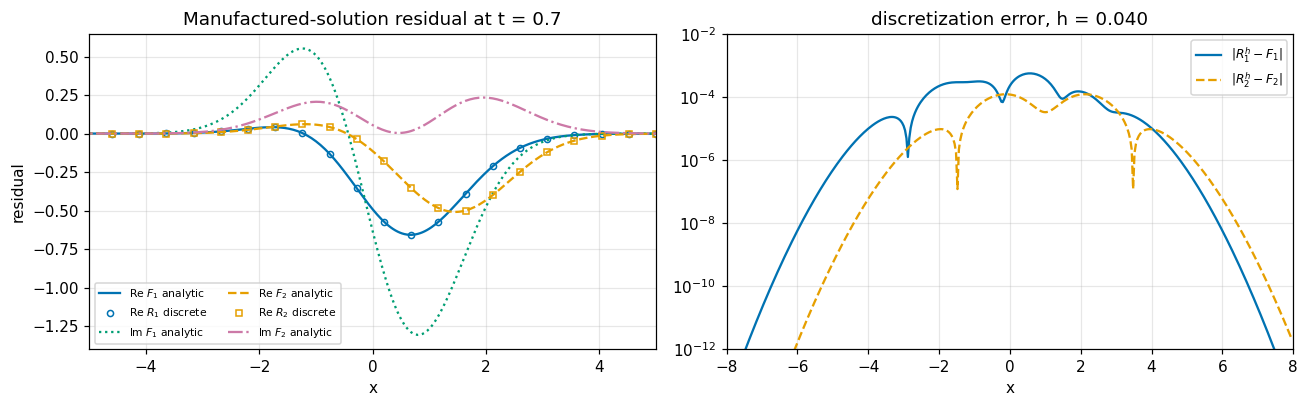

RMS norm of manufactured residual F (analytic):    0.490453
RMS norm of discrete residual R^h:                  0.490377
RMS norm of discretization error R^h - F (h=0.040): 1.693e-04
Figure 1. Left: real parts of the analytic forcing F1 (solid blue) and F2 (dashed orange), with the finite-difference residual sampled as open circles (component 1) and open squares (component 2) lying on them; imaginary parts of F1 (dotted green) and F2 (dash-dot purple). Right: pointwise error between discrete and analytic residual on a log scale (solid blue for component 1, dashed orange for component 2). It peaks where Psi_m curves most and falls to round-off in the tails.


In [10]:
pf, Ff, Vf = vsr.lambdify_vector(Psi_m), vsr.lambdify_vector(F_m), vsr.potential_numeric(V_m)
t0 = 0.7
xg = np.linspace(-8, 8, 401); h = xg[1] - xg[0]
xi, Rd = vsr.discrete_residual(pf, Vf, xg, t0, dt=h)
Fa = Ff(xi, t0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (c, ls) in enumerate([(OI['blue'], '-'), (OI['orange'], '--')]):
    ax[0].plot(xi, Fa[j].real, ls, color=c, label=f'Re $F_{j+1}$ analytic')
    ax[0].plot(xi[::12], Rd[j].real[::12], 'o' if j == 0 else 's', mfc='none', color=c, ms=4, label=f'Re $R_{j+1}$ discrete')
    ax[0].plot(xi, Fa[j].imag, ':' if j == 0 else '-.', color=OI['green'] if j == 0 else OI['purple'], label=f'Im $F_{j+1}$ analytic')
ax[0].set(xlim=(-5, 5), xlabel='x', ylabel='residual', title=f'Manufactured-solution residual at t = {t0}'); ax[0].legend(fontsize=7, ncol=2)
ax[1].semilogy(xi, np.abs(Rd[0] - Fa[0]), '-', color=OI['blue'], label='$|R_1^{h} - F_1|$')
ax[1].semilogy(xi, np.abs(Rd[1] - Fa[1]), '--', color=OI['orange'], label='$|R_2^{h} - F_2|$')
ax[1].set(xlim=(-8, 8), ylim=(1e-12, 1e-2), xlabel='x', title=f'discretization error, h = {h:.3f}'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
rms_F, rms_err = vsr.rms(Fa), vsr.rms(Rd - Fa)
print(f'RMS norm of manufactured residual F (analytic):    {rms_F:.6f}')
print(f'RMS norm of discrete residual R^h:                  {vsr.rms(Rd):.6f}')
print(f'RMS norm of discretization error R^h - F (h={h:.3f}): {rms_err:.3e}')
print('Figure 1. Left: real parts of the analytic forcing F1 (solid blue) and F2 (dashed orange), with the finite-difference '
      'residual sampled as open circles (component 1) and open squares (component 2) lying on them; imaginary parts of F1 '
      '(dotted green) and F2 (dash-dot purple). Right: pointwise error between discrete and analytic residual on a log scale '
      '(solid blue for component 1, dashed orange for component 2). It peaks where Psi_m curves most and falls to round-off in the tails.')

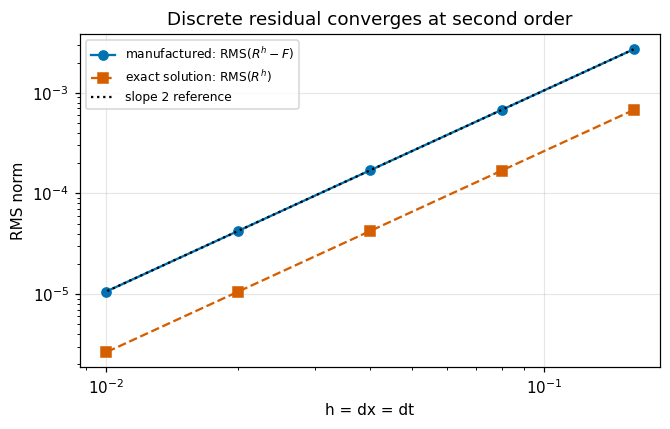

Figure 2. Log-log RMS norms against step h (dx = dt). Blue circles (solid): discrete residual minus analytic forcing for the manufactured Psi_m. Red squares (dashed): discrete residual of the exact Rabi solution, which is analytically zero but nonzero on a grid. Both follow the dotted black slope-2 line: second-order central differences.


,n,h,rms_error,observed_order,rms_exact_solution
0,101,0.16,0.002708,NaN,0.000675
1,201,0.08,0.000677,1.999124,0.000169
2,401,0.04,0.000169,2.000682,0.000042
3,801,0.02,0.000042,2.000621,0.000011
4,1601,0.01,0.000011,2.000381,0.000003


In [11]:
rows = []
for n in (101, 201, 401, 801, 1601):
    xg = np.linspace(-8, 8, n); h = xg[1] - xg[0]
    xi, Rd = vsr.discrete_residual(pf, Vf, xg, t0, dt=h)
    rows.append(dict(n=n, h=h, rms_error=vsr.rms(Rd - Ff(xi, t0))))
conv = pd.DataFrame(rows)
conv['observed_order'] = np.r_[np.nan, vsr.convergence_orders(conv.rms_error, conv.h)]
# discrete residual of the EXACT Rabi solution: nonzero on a grid, but O(h^2)
num = {hbar: 1, m: 1, omega: 1, g: sp.Rational(1, 5)}
pf_x, Vf_x = vsr.lambdify_vector(Psi_x.subs(num)), vsr.potential_numeric(V_x.subs(num))
conv['rms_exact_solution'] = [vsr.rms(vsr.discrete_residual(pf_x, Vf_x, np.linspace(-8, 8, n), 1.0, dt=16/(n-1))[1]) for n in conv.n]
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.loglog(conv.h, conv.rms_error, 'o-', color=OI['blue'], label='manufactured: RMS$(R^h-F)$')
ax.loglog(conv.h, conv.rms_exact_solution, 's--', color=OI['red'], label='exact solution: RMS$(R^h)$')
ax.loglog(conv.h, conv.rms_error.iloc[0]*(conv.h/conv.h.iloc[0])**2, ':', color=OI['black'], label='slope 2 reference')
ax.set(xlabel='h = dx = dt', ylabel='RMS norm', title='Discrete residual converges at second order'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 2. Log-log RMS norms against step h (dx = dt). Blue circles (solid): discrete residual minus analytic forcing '
      'for the manufactured Psi_m. Red squares (dashed): discrete residual of the exact Rabi solution, which is analytically '
      'zero but nonzero on a grid. Both follow the dotted black slope-2 line: second-order central differences.')
conv

## 7. Lean proof obligations

**Compiled (core Lean 4):** the algebra behind the split, using complex numbers with integer parts (Gaussian integers):
`i_mul_split` ($i(u+iv)=-v+iu$), `real_diag_split`, `coupling_split` ($W\psi_2$), and `hermitian_form_real` / `diagonal_form_real` ($\Psi^\dagger V\Psi$ is real when $V$ is Hermitian, the step behind conservation of probability). The cell runs `lean` and reports the actual exit code. If Lean isn't installed, it says the file was **not** verified.

**Not compiled:** the analytic statements (the residual is zero, the stationary pair, norm conservation) need Mathlib's `Real`, `Complex`, derivatives and integrals. They're printed below as `sorry` stubs, i.e. open obligations, not results.

In [12]:
LEAN_SRC = r'''
-- generated by vector_schrodinger_residual.ipynb (core Lean 4, no Mathlib)
-- Complex numbers with integer parts (Gaussian integers) model the algebra of the split.

structure GI where
  re : Int
  im : Int

namespace GI
def mul (z w : GI) : GI := ⟨z.re * w.re - z.im * w.im, z.re * w.im + z.im * w.re⟩
def add (z w : GI) : GI := ⟨z.re + w.re, z.im + w.im⟩
def conj (z : GI) : GI := ⟨z.re, -z.im⟩
def I : GI := ⟨0, 1⟩
def ofInt (a : Int) : GI := ⟨a, 0⟩
end GI

open GI

-- (P1) the real/imaginary split of i*dPsi/dt: i (u + i v) = -v + i u
theorem i_mul_split (u v : Int) : mul I ⟨u, v⟩ = ⟨-v, u⟩ := by
  simp [mul, I]

-- (K1/K2) a real diagonal entry times psi keeps re and im separate
theorem real_diag_split (a u v : Int) : mul (ofInt a) ⟨u, v⟩ = ⟨a * u, a * v⟩ := by
  simp [mul, ofInt]

-- (K3/K4) W psi2 = (a + i b)(u2 + i v2): the coupling terms in Re R1 and Im R1
theorem coupling_split (a b u v : Int) : mul ⟨a, b⟩ ⟨u, v⟩ = ⟨a * u - b * v, a * v + b * u⟩ := by
  simp [mul]

-- (N2) Hermitian V => Psi^dagger V Psi is real: the off-diagonal pair
-- conj(p) W q + conj(q) conj(W) p has zero imaginary part.  This is the algebraic step
-- behind conservation of total probability.
theorem hermitian_form_real (p q w : GI) :
    (add (mul (mul (conj p) w) q) (mul (mul (conj q) (conj w)) p)).im = 0 := by
  cases p; cases q; cases w
  simp only [add, mul, conj, Int.mul_add, Int.sub_eq_add_neg, Int.mul_neg, Int.neg_neg,
    Int.mul_comm, Int.mul_left_comm]
  omega

-- (K1) diagonal part: conj(p) a p is real for real a
theorem diagonal_form_real (a : Int) (p : GI) : (mul (mul (conj p) (ofInt a)) p).im = 0 := by
  cases p
  simp only [mul, conj, ofInt, Int.mul_zero, Int.sub_zero, Int.mul_add, Int.mul_neg,
    Int.mul_comm, Int.mul_left_comm]
  omega
'''
MATHLIB_STUBS = r'''
-- NOT COMPILED: Mathlib-style proof obligations for the analytic statements (need Real, Complex,
-- derivatives and integrals). Each `sorry` is an open obligation, not a verified fact.
-- import Mathlib
-- open Complex Real
-- variable (ħ m ω g : ℝ) (hħ : 0 < ħ) (hm : 0 < m) (hω : 0 < ω)
--
-- /-- X1: the Rabi-oscillator vector solves i ħ ∂ₜΨ = HΨ pointwise. -/
-- theorem rabi_residual_zero (x t : ℝ) : vecResidual ħ m (rabiPsi ħ m ω g) (coupledV m ω g) x t = 0 := by
--   sorry
--
-- /-- S1: φ₀ (1, ±1)/√2 is a stationary state with E = ħω/2 ± g. -/
-- theorem stationary_pm (s : ℝ) (hs : s = 1 ∨ s = -1) (x : ℝ) :
--     statResidual ħ m (pmPsi ħ m ω s) (coupledV m ω g) (ħ * ω / 2 + s * g) x = 0 := by
--   sorry
--
-- /-- N2: Hermitian V ⇒ d/dt ∫ Ψ†Ψ dx = 0 for solutions decaying at ±∞. -/
-- theorem norm_conserved (Ψ : ℝ → ℝ → Fin 2 → ℂ) (hsol : IsSolution ħ m V Ψ) (hherm : IsHermitian V)
--     (hdecay : DecaysAtInfinity Ψ) : deriv (fun t => ∫ x, ‖Ψ x t‖ ^ 2) = 0 := by
--   sorry
'''

lean_file = pathlib.Path.cwd() / 'vector_schrodinger_residual.lean'
lean_file.write_text(LEAN_SRC.strip() + '\n', encoding='utf-8')
n_thm = LEAN_SRC.count('theorem ')
if shutil.which('lean'):
    r = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
    log = (r.stdout + r.stderr).strip()
    lean_ok = r.returncode == 0 and 'sorry' not in log
    print(f'{lean_file.name}: exit code {r.returncode}; {n_thm} theorems')
    print(log or 'no errors or warnings: every theorem in this file was checked by the Lean kernel')
else:
    lean_ok = False
    print('lean not found on PATH: the file was written but NOT compiled, so nothing is verified')
print('\nUncompiled Mathlib stubs (open obligations):')
print(MATHLIB_STUBS.strip())

vector_schrodinger_residual.lean: exit code 0; 5 theorems
no errors or warnings: every theorem in this file was checked by the Lean kernel

Uncompiled Mathlib stubs (open obligations):
-- NOT COMPILED: Mathlib-style proof obligations for the analytic statements (need Real, Complex,
-- derivatives and integrals). Each `sorry` is an open obligation, not a verified fact.
-- import Mathlib
-- open Complex Real
-- variable (ħ m ω g : ℝ) (hħ : 0 < ħ) (hm : 0 < m) (hω : 0 < ω)
--
-- /-- X1: the Rabi-oscillator vector solves i ħ ∂ₜΨ = HΨ pointwise. -/
-- theorem rabi_residual_zero (x t : ℝ) : vecResidual ħ m (rabiPsi ħ m ω g) (coupledV m ω g) x t = 0 := by
--   sorry
--
-- /-- S1: φ₀ (1, ±1)/√2 is a stationary state with E = ħω/2 ± g. -/
-- theorem stationary_pm (s : ℝ) (hs : s = 1 ∨ s = -1) (x : ℝ) :
--     statResidual ħ m (pmPsi ħ m ω s) (coupledV m ω g) (ħ * ω / 2 + s * g) x = 0 := by
--   sorry
--
-- /-- N2: Hermitian V ⇒ d/dt ∫ Ψ†Ψ dx = 0 for solutions decaying at ±∞. -/
-- theorem norm_

## 8. Isolation table

Each row isolates one component, derivative, coupling term, condition, or backend. The `verification` column is **computed when the notebook runs** (SymPy simplification, limit, or integral); it isn't typed in by hand. The Lean row reflects the compile result above.

In [13]:
iso = pd.DataFrame(vsr.isolation_rows())
iso.loc[len(iso)] = dict(id='L1', equation_or_term='i_mul_split ... hermitian_form_real (Gaussian-integer model)',
                         role='Lean proof obligations (algebraic)', units='-',
                         verification=('PASS: compiled, ' if lean_ok else 'NOT VERIFIED: ') + f'{n_thm} theorems; analytic stubs open (sorry)')
assert not iso.verification.str.startswith('FAIL').any()
iso

,id,equation_or_term,role,units,verification
0,C1,"psi1(x,t) = u1 + i v1",component (internal state 1),m^-1/2,PASS: enters R1 directly and R2 via W*
1,C2,"psi2(x,t) = u2 + i v2",component (internal state 2),m^-1/2,PASS: enters R2 directly and R1 via W
2,D1,i hbar dPsi/dt,time derivative,J m^-1/2,PASS: i hbar d/dt e^{-iEt/hbar} = E
3,D2,(hbar^2/2m) d^2Psi/dx^2,kinetic (dispersion) term,J m^-1/2,PASS: plane wave gives -hbar^2 k^2/2m
4,K1,V11 psi1,"diagonal potential, state 1",J m^-1/2,PASS: V11 real
5,K2,V22 psi2,"diagonal potential, state 2",J m^-1/2,PASS: V22 real
6,K3,"W psi2 in R1, W = a + i b",coupling term,J m^-1/2,"PASS: a, b in R1"
7,K4,W* psi1 in R2,Hermitian partner of coupling,J m^-1/2,PASS: V - V^dagger = 0
8,P1,"Re R1, Im R1, Re R2, Im R2",four real PDE residuals,J m^-1/2,PASS: Re + i Im reconstructs R
9,X1,"R[phi0 e^{-iE0t/hbar} (cos gt/hbar, -i sin gt/hbar)]",exact (Rabi) solution,J m^-1/2,PASS: analytic residual = 0


## 9. Optional: CUDA-Q (one-qubit Rabi evolution)

Because the coupling in §4 doesn't depend on $x$, the internal part of the exact solution is a **one-qubit** problem: $H_\text{int}=g\,\sigma_x$, so $U(t)=e^{-ig\sigma_xt/\hbar}=R_x(2gt/\hbar)$, and starting from $|0\rangle=[1,0]^T$, $\langle\sigma_z\rangle=\cos(2gt/\hbar)=|\psi_1|^2-|\psi_2|^2$ (after integrating out $\varphi_0$). CUDA-Q can run that circuit on a simulator or a QPU. It doesn't touch the spatial PDE: the spatial factor $\varphi_0$ and the residual come from §4–§6.

cudaq not installed: CUDA-Q cell skipped; CPU propagator (scipy expm) used as the reference.
To enable: install the cuda-quantum package for your platform (Linux/WSL or the NVIDIA container); not needed for any PDE result here.


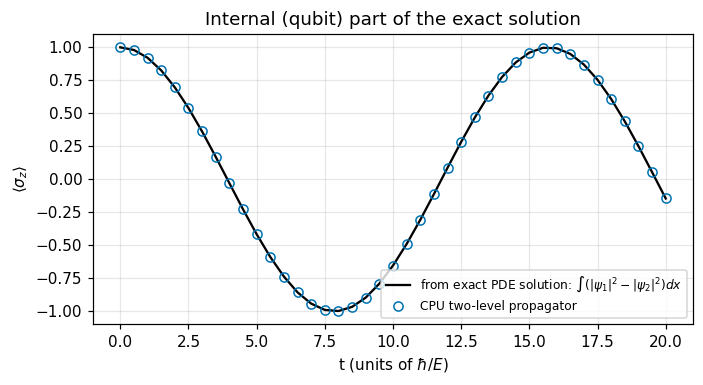

max |CPU - PDE| = 4.4e-16
Figure 3. Population difference <sigma_z> against time for g = 0.2. Solid black is computed from the exact two-component PDE solution by integrating over x; open blue circles are the CPU one-qubit propagator. They coincide on the curve cos(2 g t). CUDA-Q points (red crosses) would appear only if cudaq were installed.


In [14]:
gnum, times = 0.2, np.linspace(0, 20, 41)
z_cpu = vsr.rabi_z_expectation_cpu(gnum, times)
dens = sp.lambdify(t, sp.integrate(sp.Abs(Psi_x[0])**2 - sp.Abs(Psi_x[1])**2, (x, -sp.oo, sp.oo)).subs(num), 'numpy')
z_pde = np.broadcast_to(dens(times), times.shape)
if vsr.cudaq_available():
    z_q = vsr.rabi_z_expectation_cudaq(gnum, times)
    print('cudaq detected: <Z>(t) from a CUDA-Q kernel rx(2 g t)')
else:
    z_q = None
    print('cudaq not installed: CUDA-Q cell skipped; CPU propagator (scipy expm) used as the reference.')
    print('To enable: install the cuda-quantum package for your platform (Linux/WSL or the NVIDIA container); not needed for any PDE result here.')
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(times, z_pde, '-', color=OI['black'], label='from exact PDE solution: $\\int(|\\psi_1|^2-|\\psi_2|^2)dx$')
ax.plot(times, z_cpu, 'o', mfc='none', color=OI['blue'], label='CPU two-level propagator')
if z_q is not None:
    ax.plot(times, z_q, 'x', color=OI['red'], label='CUDA-Q observe')
ax.set(xlabel='t (units of $\\hbar/E$)', ylabel='$\\langle\\sigma_z\\rangle$', title='Internal (qubit) part of the exact solution'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f'max |CPU - PDE| = {np.max(np.abs(z_cpu - z_pde)):.1e}' + ('' if z_q is None else f'; max |CUDA-Q - PDE| = {np.max(np.abs(z_q - z_pde)):.1e}'))
print('Figure 3. Population difference <sigma_z> against time for g = 0.2. Solid black is computed from the exact two-component '
      'PDE solution by integrating over x; open blue circles are the CPU one-qubit propagator. They coincide on the curve '
      'cos(2 g t). CUDA-Q points (red crosses) would appear only if cudaq were installed.')

## 10. Optional: cuQuantum

cuQuantum is NVIDIA's GPU library layer for quantum simulation: **cuStateVec** (state vectors) and **cuTensorNet** (tensor-network contraction). It speeds up large quantum-state and tensor-network calculations. **It isn't needed for anything symbolic or for the finite-difference residuals here**, and it doesn't compute a PDE residual. The only place it could fit in this notebook is the tiny contraction $U_{ij}\psi_j$ below.

In [15]:
U = vsr.two_level_propagator(gnum, 3.0)
psi0 = np.array([1, 0], complex)
ref = U @ psi0
if vsr.cuquantum_available():
    try:
        res = vsr.apply_propagator_cuquantum(U, psi0)
        print('cuquantum detected: contract("ij,j->i") =', res, '| max diff vs NumPy:', np.max(np.abs(res - ref)))
    except Exception as exc:     # report the actual failure (e.g. no GPU) instead of claiming a result
        print('cuquantum import worked but contraction failed:', type(exc).__name__, exc)
else:
    print('cuquantum not installed: skipped. It is a GPU tensor-network / state-vector library layer, and is not required')
    print('for the symbolic PDE residual, the real/imaginary split, or the finite-difference checks in this notebook.')
print('NumPy reference U psi0 =', np.round(ref, 12))

cuquantum not installed: skipped. It is a GPU tensor-network / state-vector library layer, and is not required
for the symbolic PDE residual, the real/imaginary split, or the finite-difference checks in this notebook.
NumPy reference U psi0 = [0.82533561+0.j         0.        -0.56464247j]


## 11. Validation checklist

The checks below are re-evaluated when the notebook runs:

In [16]:
checks = {
    'V is Hermitian (V - V^dagger = 0)': vsr.is_hermitian(V_g),
    'Re R + i Im R reconstructs R (four real PDEs)': all(e == 0 for e in recon),
    'sp.re / sp.im agree with complex values on the manufactured forcing': bool(np.allclose(df_reim.re_via_sp_re, df_reim.re_direct)),
    'analytic residual of the Rabi solution is exactly 0': R_x == sp.zeros(2, 1),
    'stationary residual 0 for E = hbar w/2 +- g, nonzero for E0':
        all(vsr.simplify_matrix(vsr.stationary_residual(P, vsr.coupled_oscillator_potential(), En)) == sp.zeros(2, 1)
            for P, En in vsr.stationary_pair()) and RE_bad != sp.zeros(2, 1),
    'IC, BC and normalization (integral = 1) hold': vsr.total_probability(Psi_x) == 1,
    'discrete eigenvalues within 1e-4 of (n+1/2) +- g': bool(df_eig.abs_error.max() < 1e-4),
    'manufactured discrete residual converges at order 2 (+-0.05)': bool(np.allclose(conv.observed_order.dropna(), 2, atol=0.05)),
    'CPU qubit propagator matches the PDE population difference': bool(np.allclose(z_cpu, z_pde)),
    'Lean file compiled with no errors and no sorry': lean_ok,
}
for k, v in checks.items():
    print(('PASS ' if v else 'FAIL ') + k)
assert all(checks.values())

PASS V is Hermitian (V - V^dagger = 0)
PASS Re R + i Im R reconstructs R (four real PDEs)
PASS sp.re / sp.im agree with complex values on the manufactured forcing
PASS analytic residual of the Rabi solution is exactly 0
PASS stationary residual 0 for E = hbar w/2 +- g, nonzero for E0
PASS IC, BC and normalization (integral = 1) hold
PASS discrete eigenvalues within 1e-4 of (n+1/2) +- g
PASS manufactured discrete residual converges at order 2 (+-0.05)
PASS CPU qubit propagator matches the PDE population difference
PASS Lean file compiled with no errors and no sorry


### Analytic vs discretized residual vs quantum backend

| | **Analytic residual** | **Discretized residual** | **Quantum-simulation backend** |
|---|---|---|---|
| object | SymPy expression $R[\Psi]$ | array $R^h$ on a grid | qubit state / tensor network |
| exact solution gives | exactly $0$ | $O(h^2)$, not $0$ | n/a: no PDE in it |
| what it verifies | the formula is a solution | the discretization is consistent (MMS) | the internal two-level dynamics |
| tools here | SymPy | NumPy, SciPy sparse | CPU propagator; CUDA-Q / cuQuantum only if installed |
| speedup from GPUs | no | yes in principle (not used or benchmarked here) | yes, for large qubit counts / tensor networks |

**References** (from memory; verify before citing)
[1] P. J. Roache, "Code verification by the method of manufactured solutions," *J. Fluids Eng.*, vol. 124, no. 1, pp. 4–10, 2002.
[2] D. J. Griffiths and D. F. Schroeter, *Introduction to Quantum Mechanics*, 3rd ed. Cambridge, U.K.: Cambridge Univ. Press, 2018.
[3] NVIDIA, "CUDA-Q" and "cuQuantum SDK" documentation, developer.nvidia.com.

**Limitations.** CUDA-Q and cuQuantum weren't installed when this notebook was run, so their code paths are written but haven't been run. No benchmark numbers are reported. The Lean proofs cover integer-coefficient algebra only. The analytic obligations are open `sorry` stubs.